# SPARK Reprocessing — IKK-SPK-novel (dim reporter)

Reprocesses polyIC and TNFa FOVs for IKK-SPK-novel using an improved
two-threshold puncta detection that handles dimmer images:
1. Find puncta cores at per-cell 97th percentile
2. Expand each core to connected pixels above absolute floor (800)
3. Filter by size and mean intensity

Existing HDF5 entries are deleted before reprocessing so results are overwritten.

In [5]:
import sys, os, json
import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd

sys.path.append('.')           # spark_utils.py must be in the same directory
sys.path.append('../data-registry/cli/')

from spark_utils import (
    load_tiff_as_grayscale, make_read_frame,
    run_cellsam_segmentation,
    postprocess_masks, interpolate_missing_masks,
    quantify_spark, normalise_spark,
    save_to_hdf5,
)


In [6]:
# ── load CellSAM model (run once) ───────────────────────────────────────
model_weight_path = './.cellsam_assets/mixed_model_inference_balanced.pth'
model = torch.load(model_weight_path, map_location=torch.device('cpu'))
model.bbox_threshold = 0.4 / 1.05
model.mask_threshold = 0.4 / 5.05
model.iou_threshold  = 0.5 / 1.05
model = model.eval().cuda()


In [13]:
# ── reprocess IKK-SPK-novel polyIC and TNFa with improved puncta detection ────
import os, h5py
import pandas as pd

OUTPUT_H5 = '${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5'
DATADIR   = '${SPARK_ACQUISITION_ROOT}/ExRai-imaging'

# ── runs to reprocess ─────────────────────────────────────────────────────────
# These were quantified with min_puncta_mean_int=2600 which is too high for
# the dimmer IKK-SPK-novel reporter. Signal was all-zero. Reprocess with the
# improved two-threshold method.
REPROCESS = [
    # ── 20240815_cy_plate4 ────────────────────────────────────────────────────
    {'run_key': '240815_plate4_xy29', 'reporter': 'IKK-SPK-novel', 'condition': 'blank',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy29.tif'},
    {'run_key': '240815_plate4_xy30', 'reporter': 'IKK-SPK-novel', 'condition': 'blank',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy30.tif'},
    {'run_key': '240815_plate4_xy33', 'reporter': 'IKK-SPK-novel', 'condition': 'GSK-8612',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy33.tif'},
    {'run_key': '240815_plate4_xy34', 'reporter': 'IKK-SPK-novel', 'condition': 'GSK-8612',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy34.tif'},
    {'run_key': '240815_plate4_xy39', 'reporter': 'IKK-SPK-novel', 'condition': 'polyIC',      # NEW
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy39.tif'},
    {'run_key': '240815_plate4_xy40', 'reporter': 'IKK-SPK-novel', 'condition': 'polyIC',      # NEW
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy40.tif'},
    {'run_key': '240815_plate4_xy41', 'reporter': 'IKK-SPK-novel', 'condition': 'polyIC',      # NEW
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy41.tif'},
    {'run_key': '240815_plate4_xy42', 'reporter': 'IKK-SPK-novel', 'condition': 'polyIC',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy42.tif'},
    {'run_key': '240815_plate4_xy53', 'reporter': 'IKK-SPK-novel', 'condition': 'diABZI',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy53.tif'},
    {'run_key': '240815_plate4_xy54', 'reporter': 'IKK-SPK-novel', 'condition': 'diABZI',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy54.tif'},
    {'run_key': '240815_plate4_xy55', 'reporter': 'IKK-SPK-novel', 'condition': 'polyIC',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy55.tif'},
    {'run_key': '240815_plate4_xy56', 'reporter': 'IKK-SPK-novel', 'condition': 'polyIC',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy56.tif'},
    {'run_key': '240815_plate4_xy57', 'reporter': 'IKK-SPK-novel', 'condition': 'polyIC',      # NEW
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy57.tif'},
    {'run_key': '240815_plate4_xy58', 'reporter': 'IKK-SPK-novel', 'condition': 'polyIC',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy58.tif'},
    {'run_key': '240815_plate4_xy59', 'reporter': 'IKK-SPK-novel', 'condition': 'TNFa',        # NEW
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy59.tif'},
    {'run_key': '240815_plate4_xy60', 'reporter': 'IKK-SPK-novel', 'condition': 'TNFa',        # NEW
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy60.tif'},
    {'run_key': '240815_plate4_xy61', 'reporter': 'IKK-SPK-novel', 'condition': 'TNFa',        # NEW
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy61.tif'},
    {'run_key': '240815_plate4_xy62', 'reporter': 'IKK-SPK-novel', 'condition': 'TNFa',        # NEW
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy62.tif'},
    {'run_key': '240815_plate4_xy63', 'reporter': 'IKK-SPK-novel', 'condition': 'TNFa',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy63.tif'},
    {'run_key': '240815_plate4_xy64', 'reporter': 'IKK-SPK-novel', 'condition': 'TNFa',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240815_cy_plate4/20240815_cy_plate4xy64.tif'},
    # ── 20240822_cy_plate2 ────────────────────────────────────────────────────
    {'run_key': '240822_plate2_xy36', 'reporter': 'IKK-SPK-novel', 'condition': 'blank',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy36.tif'},
    {'run_key': '240822_plate2_xy37', 'reporter': 'IKK-SPK-novel', 'condition': 'blank',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy37.tif'},
    {'run_key': '240822_plate2_xy38', 'reporter': 'IKK-SPK-novel', 'condition': 'GSK-8612',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy38.tif'},
    {'run_key': '240822_plate2_xy39', 'reporter': 'IKK-SPK-novel', 'condition': 'GSK-8612',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy39.tif'},
    {'run_key': '240822_plate2_xy41', 'reporter': 'IKK-SPK-novel', 'condition': 'BMS-345541',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy41.tif'},
    {'run_key': '240822_plate2_xy44', 'reporter': 'IKK-SPK-novel', 'condition': 'TNFa',        # NEW
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy44.tif'},
    {'run_key': '240822_plate2_xy45', 'reporter': 'IKK-SPK-novel', 'condition': 'TNFa',        # NEW
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy45.tif'},
    {'run_key': '240822_plate2_xy46', 'reporter': 'IKK-SPK-novel', 'condition': 'TNFa',        # NEW
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy46.tif'},
    {'run_key': '240822_plate2_xy47', 'reporter': 'IKK-SPK-novel', 'condition': 'TNFa',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy47.tif'},
    {'run_key': '240822_plate2_xy48', 'reporter': 'IKK-SPK-novel', 'condition': 'polyIC',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy48.tif'},
    {'run_key': '240822_plate2_xy49', 'reporter': 'IKK-SPK-novel', 'condition': 'polyIC',      # NEW
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy49.tif'},
    {'run_key': '240822_plate2_xy50', 'reporter': 'IKK-SPK-novel', 'condition': 'polyIC',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy50.tif'},
    {'run_key': '240822_plate2_xy51', 'reporter': 'IKK-SPK-novel', 'condition': 'polyIC',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy51.tif'},
    {'run_key': '240822_plate2_xy52', 'reporter': 'IKK-SPK-novel', 'condition': 'polyIC',
     'filepath': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy52.tif'},
]

# ── delete existing HDF5 entries so they get reprocessed ─────────────────────
with h5py.File(OUTPUT_H5, 'a') as hf:
    for entry in REPROCESS:
        rk = entry['run_key']
        if rk in hf:
            del hf[rk]
            print(f'Deleted {rk} from HDF5')
        else:
            print(f'{rk}: not in HDF5 (will be created fresh)')

EXPERIMENTS = []
for entry in REPROCESS:
    EXPERIMENTS.append({
        'path':              entry['filepath'],
        'run_key':           entry['run_key'],
        'reporter':          entry['reporter'],
        'condition':         entry['condition'],
        'channel':           None,
        'minutes_per_frame': 4.0,
        'frame_offset_min':  0.0,
        'norm_frame':        None,
        'ctrl_cell_ids':     None,
    })

print(f'\nExperiments to reprocess: {len(EXPERIMENTS)}')
for e in EXPERIMENTS:
    print(f"  {e['run_key']:35s} {e['reporter']:20s} {e['condition']}")

# ── segmentation parameters (unchanged) ──────────────────────────────────────
SEG_PARAMS = {
    'clip_max':          3000,
    'min_cell_size_px':  5000,
    'iou_thresh':        0.5,
    'ioq_thresh':        0.2,
    'dilation_px':       20,
    'max_interp_gap':    4,
}

# ── improved puncta parameters for dim IKK-SPK-novel reporter ────────────────
PUNCTA_CELL_PERCENTILE = 97    # high percentile → puncta cores
PUNCTA_LOW_FLOOR       = 800   # absolute floor for region expansion
MIN_PUNCTA_SIZE        = 4
MAX_PUNCTA_SIZE        = 1500
MIN_PUNCTA_MEAN_INT    = 800


240815_plate4_xy29: not in HDF5 (will be created fresh)
Deleted 240815_plate4_xy30 from HDF5
Deleted 240815_plate4_xy33 from HDF5
Deleted 240815_plate4_xy34 from HDF5
240815_plate4_xy39: not in HDF5 (will be created fresh)
240815_plate4_xy40: not in HDF5 (will be created fresh)
240815_plate4_xy41: not in HDF5 (will be created fresh)
240815_plate4_xy42: not in HDF5 (will be created fresh)
Deleted 240815_plate4_xy53 from HDF5
Deleted 240815_plate4_xy54 from HDF5
240815_plate4_xy55: not in HDF5 (will be created fresh)
240815_plate4_xy56: not in HDF5 (will be created fresh)
240815_plate4_xy57: not in HDF5 (will be created fresh)
240815_plate4_xy58: not in HDF5 (will be created fresh)
240815_plate4_xy59: not in HDF5 (will be created fresh)
240815_plate4_xy60: not in HDF5 (will be created fresh)
240815_plate4_xy61: not in HDF5 (will be created fresh)
240815_plate4_xy62: not in HDF5 (will be created fresh)
240815_plate4_xy63: not in HDF5 (will be created fresh)
240815_plate4_xy64: not in HDF5


Processing: 240815_plate4_xy29  [IKK-SPK-novel / blank]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=103  max=3150  mean=191.9


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [02:06<00:00,  1.56s/it]


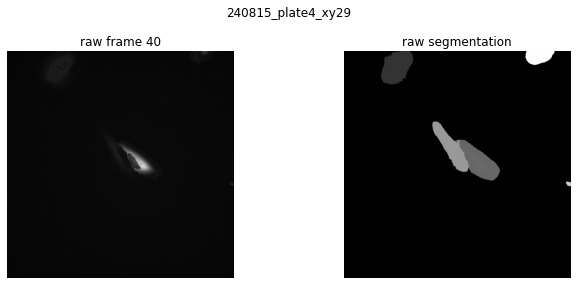

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [00:14<00:00,  5.55it/s]


  cell 3: interpolating frames 39–39
  cell 3: interpolating frames 42–42
tracked_masks: (81, 1608, 1608)  cells=[1 2 3 4]


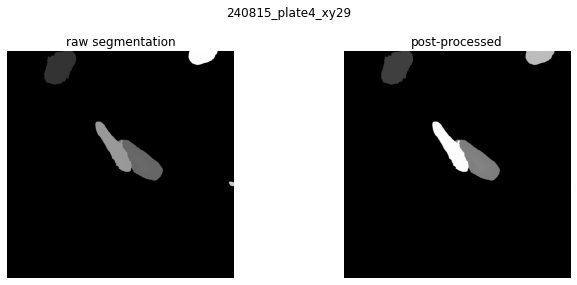

Quantifying 20240815_cy_plate4xy29.tif: 100%|██████████████████████| 81/81 [00:30<00:00,  2.69it/s]


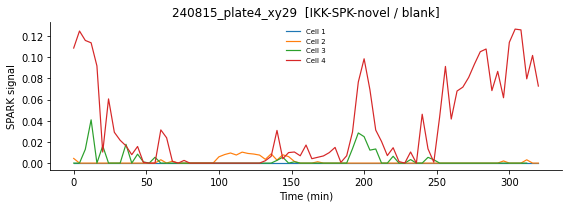

Saving run: 240815_plate4_xy29
  spark_df: 322 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [00:22<00:00,  3.60it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (355.3 MB)
  done: 240815_plate4_xy29

Processing: 240815_plate4_xy30  [IKK-SPK-novel / blank]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=104  max=2669  mean=198.9


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [02:12<00:00,  1.64s/it]


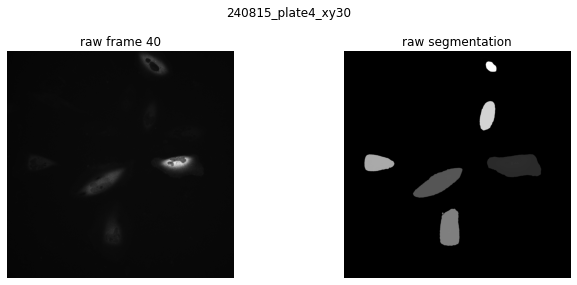

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [00:19<00:00,  4.16it/s]


  cell 4: interpolating frames 16–16
  cell 4: interpolating frames 36–36
  cell 4: gap 39–45 (7 frames) too large, skipping
  cell 4: interpolating frames 50–51
  cell 4: interpolating frames 68–68
tracked_masks: (81, 1608, 1608)  cells=[1 2 3 4 5 6]


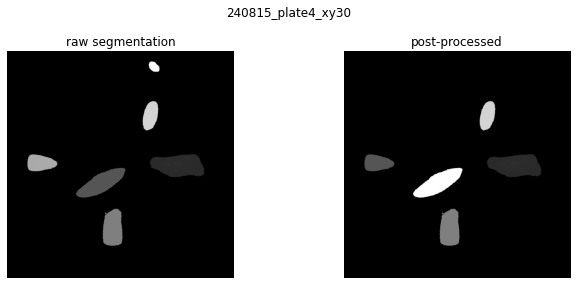

Quantifying 20240815_cy_plate4xy30.tif: 100%|██████████████████████| 81/81 [00:39<00:00,  2.03it/s]


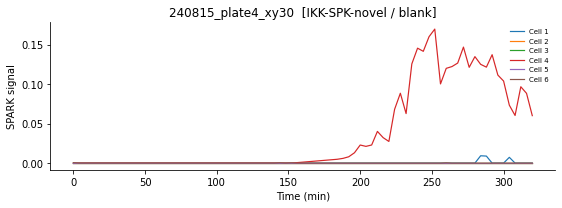

Saving run: 240815_plate4_xy30
  spark_df: 479 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [00:28<00:00,  2.84it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (356.9 MB)
  done: 240815_plate4_xy30

Processing: 240815_plate4_xy33  [IKK-SPK-novel / GSK-8612]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=102  max=3833  mean=207.8


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [03:40<00:00,  2.73s/it]


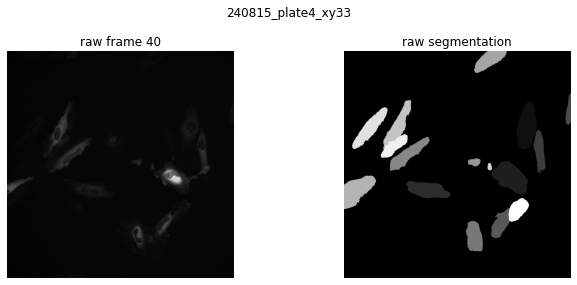

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [01:51<00:00,  1.38s/it]


  cell 2: interpolating frames 32–32
  cell 3: gap 2–13 (12 frames) too large, skipping
  cell 3: interpolating frames 25–28
  cell 3: interpolating frames 32–33
  cell 3: interpolating frames 44–44
  cell 3: gap 62–67 (6 frames) too large, skipping
  cell 4: interpolating frames 10–10
  cell 5: interpolating frames 10–10
  cell 5: interpolating frames 14–16
  cell 5: interpolating frames 26–26
  cell 7: interpolating frames 2–2
  cell 7: gap 18–27 (10 frames) too large, skipping
  cell 7: interpolating frames 33–34
  cell 7: interpolating frames 40–43
  cell 13: interpolating frames 28–29
  cell 13: interpolating frames 49–49
  cell 13: interpolating frames 54–54
  cell 13: interpolating frames 74–75
  cell 16: gap 13–17 (5 frames) too large, skipping
  cell 16: gap 20–25 (6 frames) too large, skipping
  cell 16: gap 28–35 (8 frames) too large, skipping
  cell 16: interpolating frames 37–37
  cell 16: interpolating frames 39–39
  cell 16: gap 41–45 (5 frames) too large, skipping
  cel

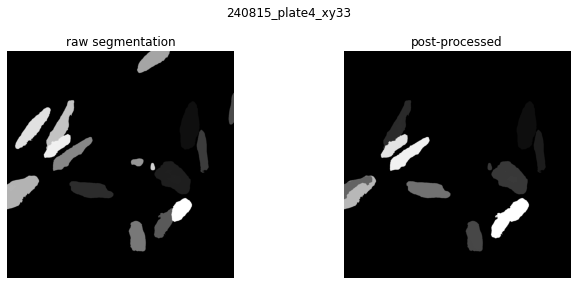

Quantifying 20240815_cy_plate4xy33.tif: 100%|██████████████████████| 81/81 [01:03<00:00,  1.28it/s]


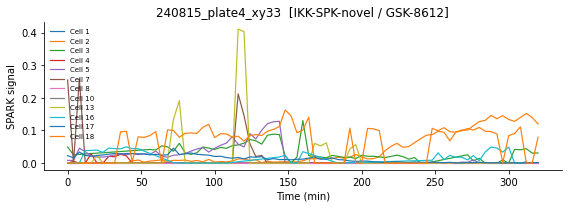

Saving run: 240815_plate4_xy33
  spark_df: 821 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [00:40<00:00,  1.99it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (360.6 MB)
  done: 240815_plate4_xy33

Processing: 240815_plate4_xy34  [IKK-SPK-novel / GSK-8612]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=104  max=3953  mean=199.4


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [03:10<00:00,  2.35s/it]


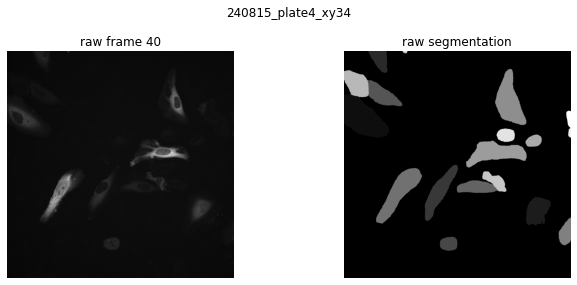

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [01:29<00:00,  1.11s/it]


  cell 2: interpolating frames 40–40
  cell 2: gap 42–68 (27 frames) too large, skipping
  cell 2: interpolating frames 70–70
  cell 2: interpolating frames 72–72
  cell 2: interpolating frames 74–74
  cell 3: interpolating frames 8–8
  cell 3: interpolating frames 25–26
  cell 4: interpolating frames 46–46
  cell 4: interpolating frames 51–51
  cell 10: interpolating frames 1–3
  cell 10: gap 9–14 (6 frames) too large, skipping
  cell 10: interpolating frames 19–19
  cell 10: interpolating frames 27–28
  cell 12: interpolating frames 4–4
  cell 12: interpolating frames 8–9
  cell 12: interpolating frames 11–11
  cell 12: gap 13–19 (7 frames) too large, skipping
  cell 13: interpolating frames 2–4
  cell 13: interpolating frames 8–8
  cell 13: interpolating frames 15–15
  cell 13: interpolating frames 17–18
  cell 13: interpolating frames 22–22
  cell 13: interpolating frames 27–30
  cell 13: interpolating frames 51–51
  cell 13: interpolating frames 53–54
tracked_masks: (81, 1608, 160

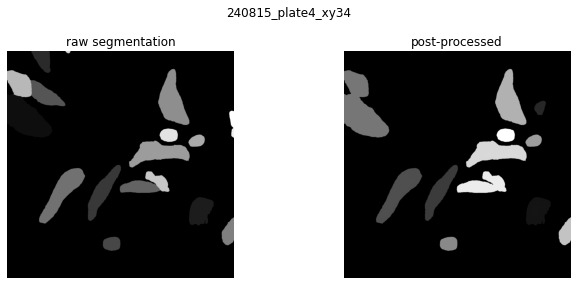

Quantifying 20240815_cy_plate4xy34.tif: 100%|██████████████████████| 81/81 [01:05<00:00,  1.23it/s]


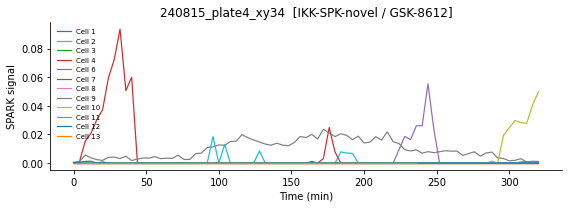

Saving run: 240815_plate4_xy34
  spark_df: 911 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [00:44<00:00,  1.80it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (363.4 MB)
  done: 240815_plate4_xy34

Processing: 240815_plate4_xy39  [IKK-SPK-novel / polyIC]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=104  max=7818  mean=205.1


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [02:46<00:00,  2.06s/it]


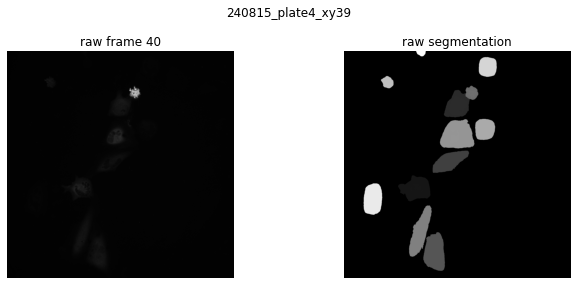

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [00:42<00:00,  1.89it/s]


  cell 1: interpolating frames 57–57
  cell 1: interpolating frames 65–66
  cell 4: interpolating frames 58–59
  cell 4: interpolating frames 66–66
  cell 4: interpolating frames 70–70
  cell 4: interpolating frames 74–75
  cell 4: interpolating frames 78–79
  cell 5: interpolating frames 51–51
  cell 5: gap 59–63 (5 frames) too large, skipping
  cell 5: interpolating frames 73–73
  cell 6: interpolating frames 68–70
  cell 7: interpolating frames 58–58
  cell 7: gap 69–73 (5 frames) too large, skipping
  cell 9: interpolating frames 35–36
  cell 9: interpolating frames 38–39
  cell 9: interpolating frames 51–54
  cell 10: gap 49–53 (5 frames) too large, skipping
  cell 10: interpolating frames 55–55
  cell 10: interpolating frames 61–61
  cell 10: interpolating frames 63–64
  cell 10: interpolating frames 68–68
tracked_masks: (81, 1608, 1608)  cells=[ 1  2  3  4  5  6  7  8  9 10]


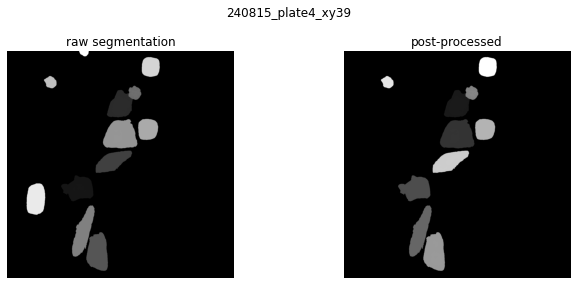

Quantifying 20240815_cy_plate4xy39.tif: 100%|██████████████████████| 81/81 [00:58<00:00,  1.40it/s]


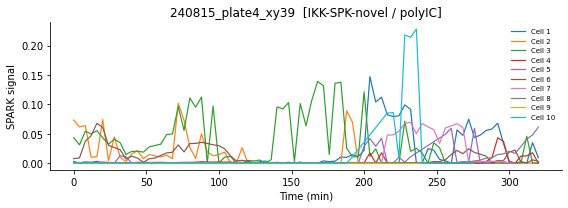

Saving run: 240815_plate4_xy39
  spark_df: 755 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [00:38<00:00,  2.11it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (366.5 MB)
  done: 240815_plate4_xy39

Processing: 240815_plate4_xy40  [IKK-SPK-novel / polyIC]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=101  max=7109  mean=209.8


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [03:17<00:00,  2.43s/it]


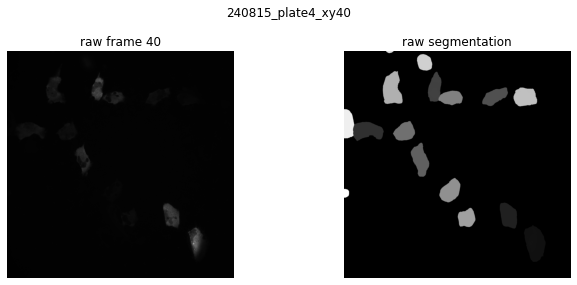

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [01:47<00:00,  1.33s/it]


  cell 4: interpolating frames 21–21
  cell 5: interpolating frames 66–66
  cell 7: interpolating frames 49–49
  cell 14: gap 1–27 (27 frames) too large, skipping
tracked_masks: (81, 1608, 1608)  cells=[ 1  2  3  4  5  6  7  8 10 11 12 14 16]


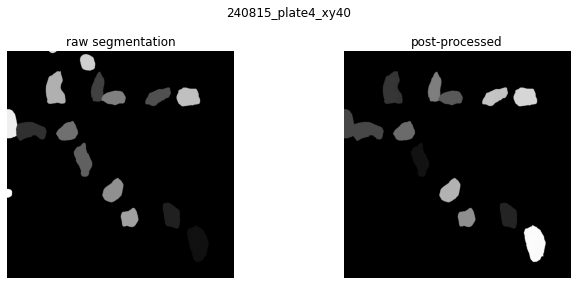

Quantifying 20240815_cy_plate4xy40.tif: 100%|██████████████████████| 81/81 [01:09<00:00,  1.17it/s]


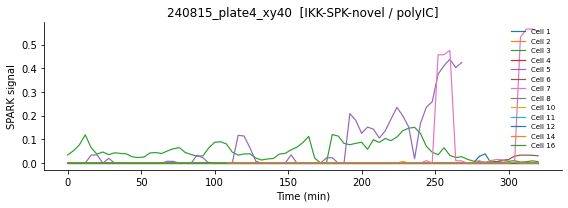

Saving run: 240815_plate4_xy40
  spark_df: 960 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [00:45<00:00,  1.79it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (369.7 MB)
  done: 240815_plate4_xy40

Processing: 240815_plate4_xy41  [IKK-SPK-novel / polyIC]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=104  max=2257  mean=186.8


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [02:06<00:00,  1.56s/it]


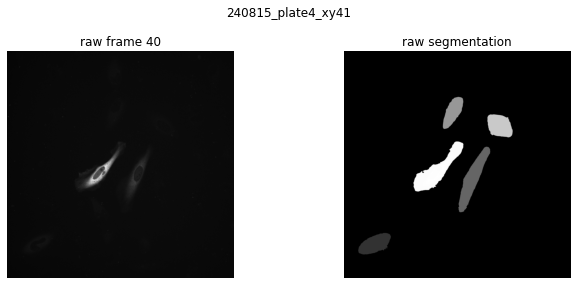

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [00:22<00:00,  3.68it/s]


  cell 2: gap 1–18 (18 frames) too large, skipping
  cell 2: gap 21–28 (8 frames) too large, skipping
  cell 2: interpolating frames 37–37
  cell 2: interpolating frames 41–41
  cell 2: gap 44–55 (12 frames) too large, skipping
  cell 3: gap 29–43 (15 frames) too large, skipping
tracked_masks: (81, 1608, 1608)  cells=[1 2 3]


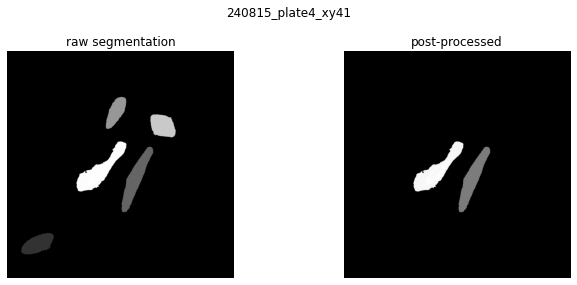

Quantifying 20240815_cy_plate4xy41.tif: 100%|██████████████████████| 81/81 [00:21<00:00,  3.84it/s]


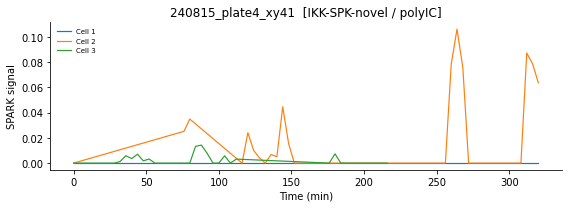

Saving run: 240815_plate4_xy41
  spark_df: 164 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [00:16<00:00,  4.82it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (370.9 MB)
  done: 240815_plate4_xy41

Processing: 240815_plate4_xy42  [IKK-SPK-novel / polyIC]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=101  max=3391  mean=188.9


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [02:52<00:00,  2.13s/it]


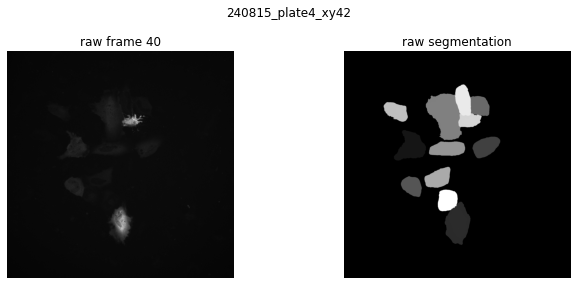

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [00:47<00:00,  1.70it/s]


  cell 6: interpolating frames 19–19
  cell 8: interpolating frames 8–8
  cell 9: interpolating frames 1–1
  cell 9: interpolating frames 11–13
  cell 9: interpolating frames 19–19
  cell 9: interpolating frames 22–23
tracked_masks: (81, 1608, 1608)  cells=[1 2 3 4 5 6 7 8 9]


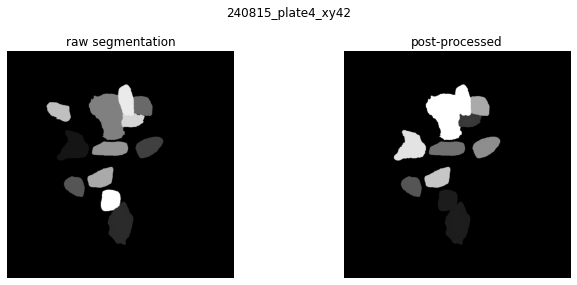

Quantifying 20240815_cy_plate4xy42.tif: 100%|██████████████████████| 81/81 [00:52<00:00,  1.54it/s]


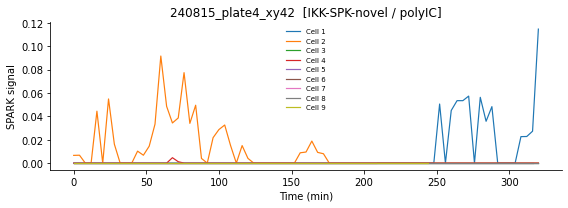

Saving run: 240815_plate4_xy42
  spark_df: 681 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [00:35<00:00,  2.25it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (372.8 MB)
  done: 240815_plate4_xy42

Processing: 240815_plate4_xy53  [IKK-SPK-novel / diABZI]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=98  max=12739  mean=213.0


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [02:36<00:00,  1.93s/it]


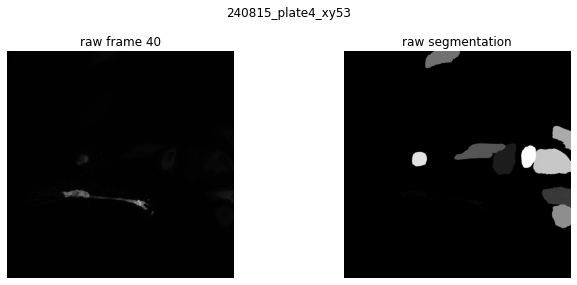

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [00:37<00:00,  2.15it/s]


  cell 3: interpolating frames 23–23
  cell 5: interpolating frames 17–17
  cell 8: interpolating frames 16–18
  cell 8: interpolating frames 25–25
  cell 8: gap 27–31 (5 frames) too large, skipping
  cell 8: interpolating frames 39–39
  cell 8: gap 41–51 (11 frames) too large, skipping
  cell 8: gap 53–59 (7 frames) too large, skipping
  cell 8: interpolating frames 61–61
  cell 9: interpolating frames 5–5
  cell 9: interpolating frames 7–8
  cell 9: interpolating frames 12–13
tracked_masks: (81, 1608, 1608)  cells=[1 2 3 4 5 6 7 8 9]


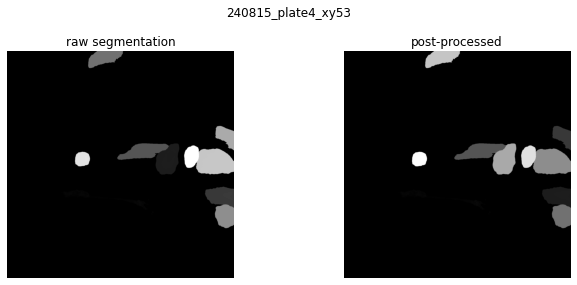

Quantifying 20240815_cy_plate4xy53.tif: 100%|██████████████████████| 81/81 [00:51<00:00,  1.58it/s]


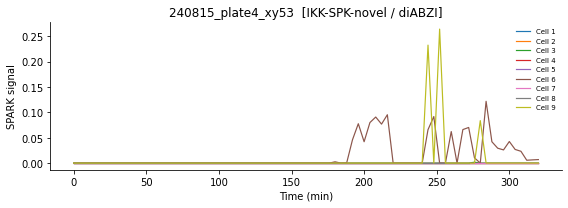

Saving run: 240815_plate4_xy53
  spark_df: 694 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [00:36<00:00,  2.22it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (374.7 MB)
  done: 240815_plate4_xy53

Processing: 240815_plate4_xy54  [IKK-SPK-novel / diABZI]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=104  max=4584  mean=236.3


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [03:04<00:00,  2.28s/it]


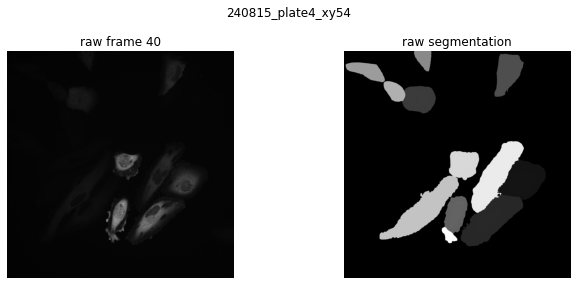

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [01:22<00:00,  1.02s/it]


  cell 4: interpolating frames 46–46
  cell 5: interpolating frames 48–48
  cell 11: interpolating frames 3–3
  cell 11: interpolating frames 66–66
  cell 11: interpolating frames 68–68
  cell 11: interpolating frames 71–72
  cell 11: interpolating frames 74–74
  cell 11: interpolating frames 76–76
  cell 11: interpolating frames 78–78
  cell 12: interpolating frames 27–30
  cell 12: interpolating frames 32–33
  cell 13: interpolating frames 40–43
  cell 13: interpolating frames 45–45
  cell 13: interpolating frames 54–57
  cell 13: interpolating frames 60–60
  cell 13: interpolating frames 62–62
  cell 13: gap 65–73 (9 frames) too large, skipping
tracked_masks: (81, 1608, 1608)  cells=[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14]


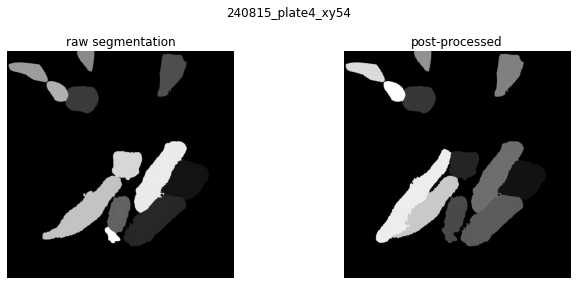

Quantifying 20240815_cy_plate4xy54.tif: 100%|██████████████████████| 81/81 [01:13<00:00,  1.11it/s]


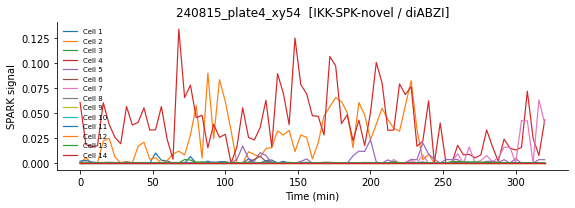

Saving run: 240815_plate4_xy54
  spark_df: 991 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [00:48<00:00,  1.67it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (378.6 MB)
  done: 240815_plate4_xy54

Processing: 240815_plate4_xy55  [IKK-SPK-novel / polyIC]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=100  max=34972  mean=216.9


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [02:14<00:00,  1.66s/it]


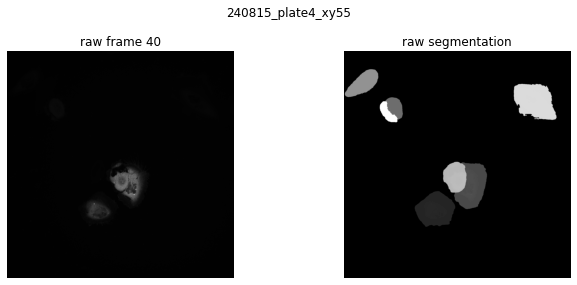

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [00:20<00:00,  4.01it/s]


  cell 2: interpolating frames 46–48
  cell 2: gap 57–69 (13 frames) too large, skipping
  cell 4: interpolating frames 50–51
  cell 4: interpolating frames 55–56
tracked_masks: (81, 1608, 1608)  cells=[1 2 3 4]


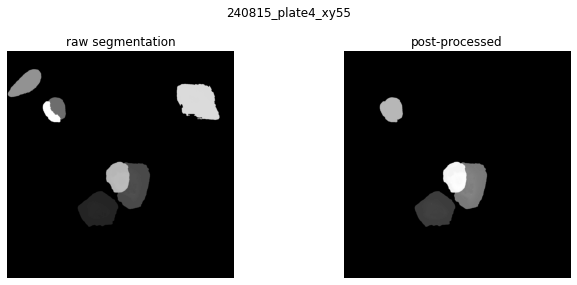

Quantifying 20240815_cy_plate4xy55.tif: 100%|██████████████████████| 81/81 [00:30<00:00,  2.69it/s]


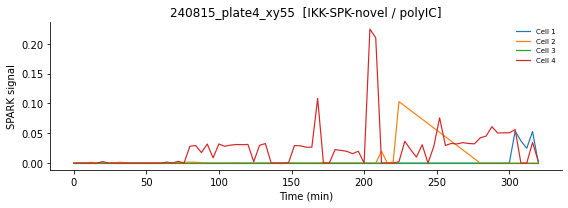

Saving run: 240815_plate4_xy55
  spark_df: 311 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [00:22<00:00,  3.64it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (380.4 MB)
  done: 240815_plate4_xy55

Processing: 240815_plate4_xy56  [IKK-SPK-novel / polyIC]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=99  max=7008  mean=192.6


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [01:59<00:00,  1.48s/it]


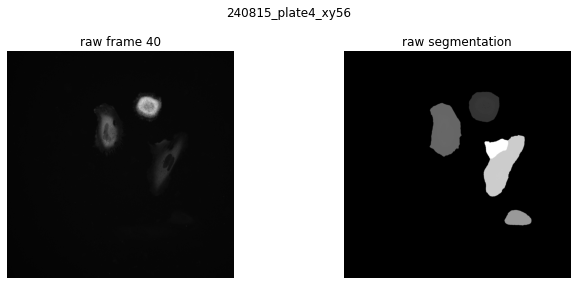

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [00:17<00:00,  4.69it/s]


  cell 3: gap 2–12 (11 frames) too large, skipping
  cell 4: interpolating frames 11–11
  cell 5: interpolating frames 10–10
  cell 5: gap 12–28 (17 frames) too large, skipping
  cell 5: interpolating frames 32–32
  cell 5: interpolating frames 37–39
  cell 5: interpolating frames 42–43
  cell 5: interpolating frames 48–48
  cell 5: interpolating frames 52–52
  cell 5: interpolating frames 62–64
  cell 5: gap 66–72 (7 frames) too large, skipping
  cell 5: interpolating frames 74–77
tracked_masks: (81, 1608, 1608)  cells=[1 2 3 4 5]


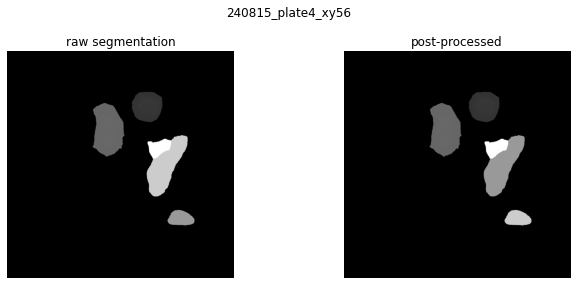

Quantifying 20240815_cy_plate4xy56.tif: 100%|██████████████████████| 81/81 [00:33<00:00,  2.43it/s]


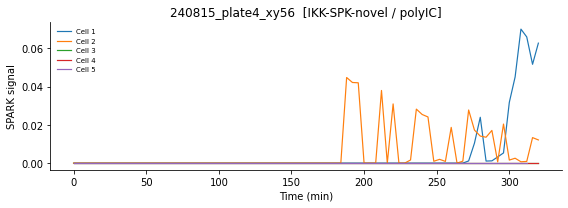

Saving run: 240815_plate4_xy56
  spark_df: 368 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [00:25<00:00,  3.21it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (382.1 MB)
  done: 240815_plate4_xy56

Processing: 240815_plate4_xy57  [IKK-SPK-novel / polyIC]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=103  max=2272  mean=195.1


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [02:18<00:00,  1.71s/it]


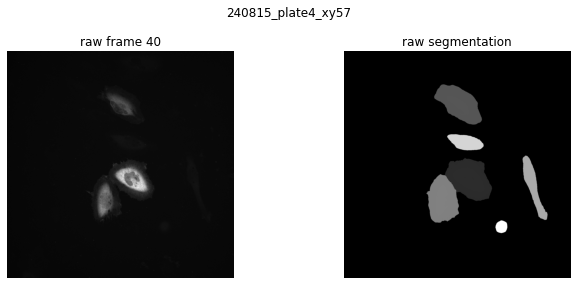

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [00:19<00:00,  4.12it/s]


  cell 5: gap 44–51 (8 frames) too large, skipping
  cell 5: gap 53–59 (7 frames) too large, skipping
tracked_masks: (81, 1608, 1608)  cells=[1 2 3 4 5 6]


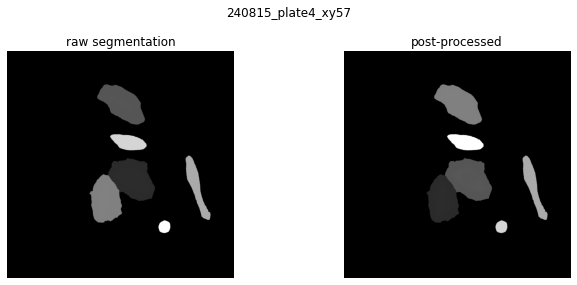

Quantifying 20240815_cy_plate4xy57.tif: 100%|██████████████████████| 81/81 [00:38<00:00,  2.12it/s]


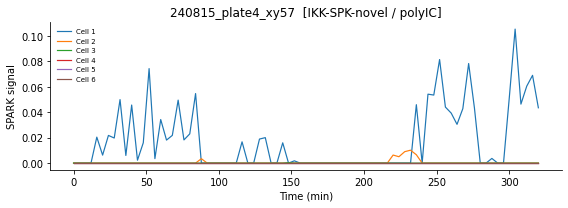

Saving run: 240815_plate4_xy57
  spark_df: 471 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [00:28<00:00,  2.88it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (384.1 MB)
  done: 240815_plate4_xy57

Processing: 240815_plate4_xy58  [IKK-SPK-novel / polyIC]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=101  max=4526  mean=252.2


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [04:27<00:00,  3.30s/it]


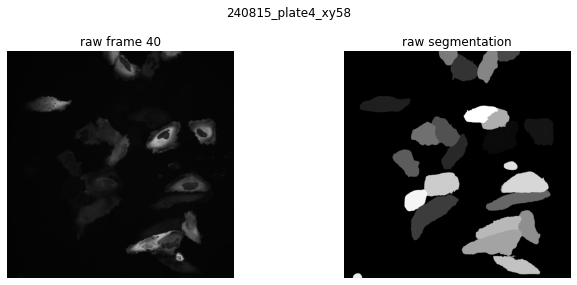

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [03:39<00:00,  2.71s/it]


  cell 2: interpolating frames 73–73
  cell 3: interpolating frames 37–39
  cell 3: gap 41–75 (35 frames) too large, skipping
  cell 11: interpolating frames 28–29
  cell 13: interpolating frames 8–8
  cell 14: interpolating frames 68–68
  cell 15: interpolating frames 73–73
  cell 16: interpolating frames 62–62
  cell 16: interpolating frames 66–66
  cell 16: interpolating frames 71–71
  cell 17: gap 2–19 (18 frames) too large, skipping
  cell 17: interpolating frames 21–21
  cell 17: interpolating frames 30–30
  cell 19: interpolating frames 33–33
  cell 19: gap 39–48 (10 frames) too large, skipping
  cell 19: gap 50–54 (5 frames) too large, skipping
  cell 20: interpolating frames 16–17
  cell 20: gap 46–54 (9 frames) too large, skipping
  cell 21: gap 1–9 (9 frames) too large, skipping
  cell 21: interpolating frames 11–12
  cell 21: interpolating frames 14–15
  cell 21: gap 18–35 (18 frames) too large, skipping
tracked_masks: (81, 1608, 1608)  cells=[ 1  2  3  4  5  6  7  8  9 10 

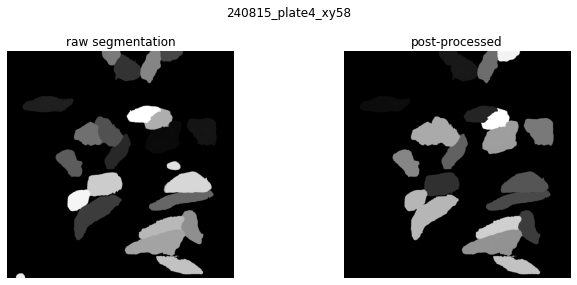

Quantifying 20240815_cy_plate4xy58.tif: 100%|██████████████████████| 81/81 [01:44<00:00,  1.28s/it]


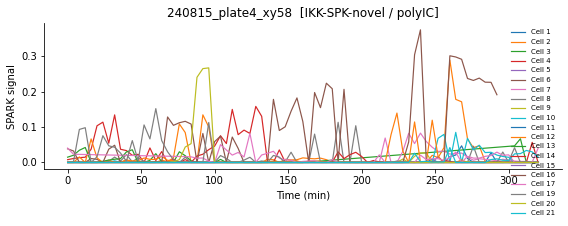

Saving run: 240815_plate4_xy58
  spark_df: 1495 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [01:05<00:00,  1.23it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (389.5 MB)
  done: 240815_plate4_xy58

Processing: 240815_plate4_xy59  [IKK-SPK-novel / TNFa]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=102  max=4301  mean=206.6


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [02:17<00:00,  1.69s/it]


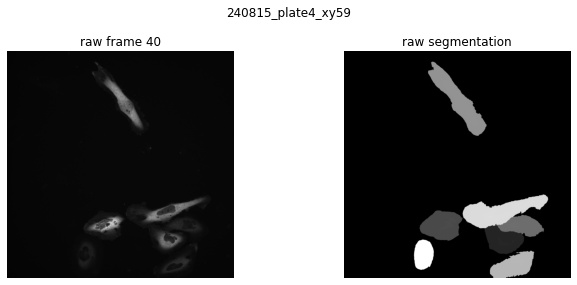

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [00:36<00:00,  2.25it/s]


  cell 2: interpolating frames 39–39
  cell 5: interpolating frames 19–19
  cell 5: interpolating frames 23–23
tracked_masks: (81, 1608, 1608)  cells=[1 2 3 4 5 6 7]


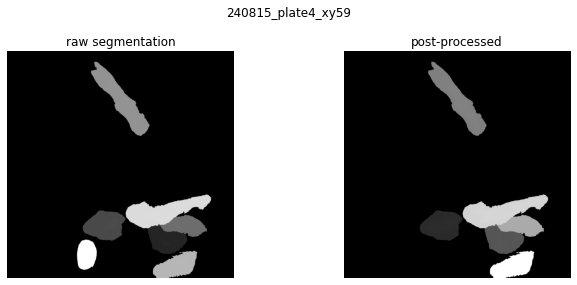

Quantifying 20240815_cy_plate4xy59.tif: 100%|██████████████████████| 81/81 [00:44<00:00,  1.83it/s]


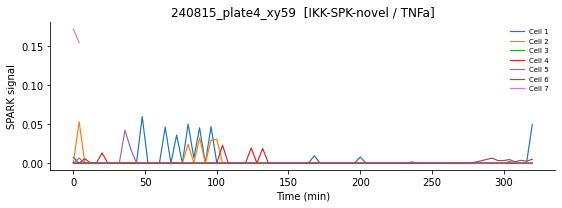

Saving run: 240815_plate4_xy59
  spark_df: 488 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [00:28<00:00,  2.82it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (392.1 MB)
  done: 240815_plate4_xy59

Processing: 240815_plate4_xy60  [IKK-SPK-novel / TNFa]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=99  max=9976  mean=254.6


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [03:57<00:00,  2.93s/it]


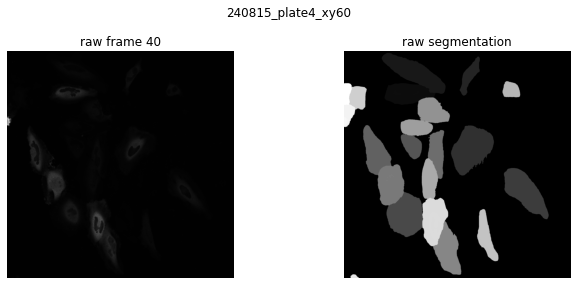

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [02:40<00:00,  1.98s/it]


  cell 10: interpolating frames 27–27
  cell 11: interpolating frames 55–55
  cell 14: interpolating frames 69–71
  cell 16: gap 2–29 (28 frames) too large, skipping
  cell 18: interpolating frames 26–26
tracked_masks: (81, 1608, 1608)  cells=[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 18]


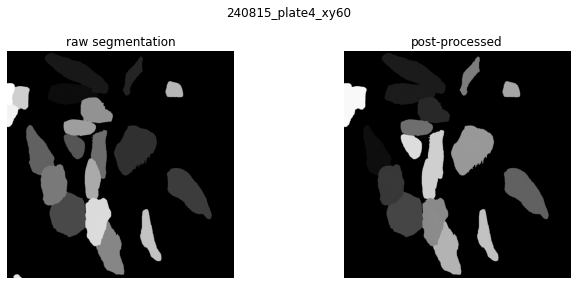

Quantifying 20240815_cy_plate4xy60.tif: 100%|██████████████████████| 81/81 [01:30<00:00,  1.12s/it]


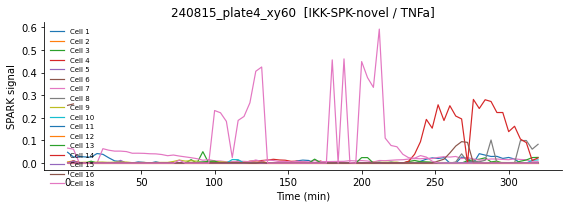

Saving run: 240815_plate4_xy60
  spark_df: 1270 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [00:58<00:00,  1.40it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (397.7 MB)
  done: 240815_plate4_xy60

Processing: 240815_plate4_xy61  [IKK-SPK-novel / TNFa]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=99  max=12075  mean=238.4


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [04:58<00:00,  3.69s/it]


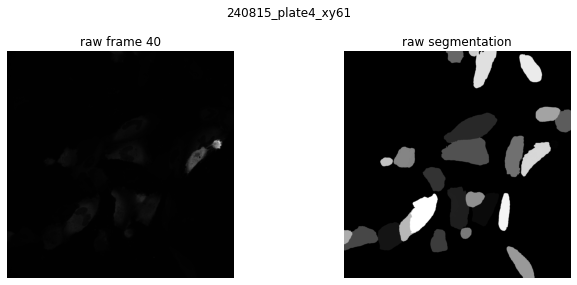

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [04:51<00:00,  3.60s/it]


  cell 2: interpolating frames 16–19
  cell 2: gap 23–31 (9 frames) too large, skipping
  cell 2: interpolating frames 34–35
  cell 2: interpolating frames 38–39
  cell 2: interpolating frames 42–43
  cell 2: interpolating frames 49–49
  cell 2: interpolating frames 61–61
  cell 2: interpolating frames 63–64
  cell 3: gap 5–17 (13 frames) too large, skipping
  cell 3: interpolating frames 22–25
  cell 3: interpolating frames 27–27
  cell 3: interpolating frames 30–31
  cell 3: interpolating frames 76–77
  cell 4: interpolating frames 63–63
  cell 6: interpolating frames 72–72
  cell 7: interpolating frames 21–21
  cell 9: interpolating frames 69–69
  cell 10: interpolating frames 63–64
  cell 13: gap 2–71 (70 frames) too large, skipping
  cell 13: interpolating frames 73–74
  cell 15: interpolating frames 19–19
  cell 16: interpolating frames 19–19
  cell 17: interpolating frames 22–23
  cell 17: gap 27–42 (16 frames) too large, skipping
  cell 17: interpolating frames 45–48
  cell 17:

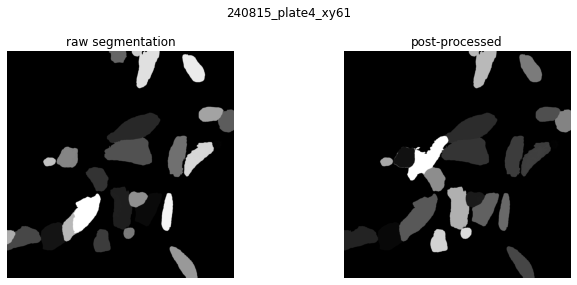

Quantifying 20240815_cy_plate4xy61.tif: 100%|██████████████████████| 81/81 [01:49<00:00,  1.35s/it]


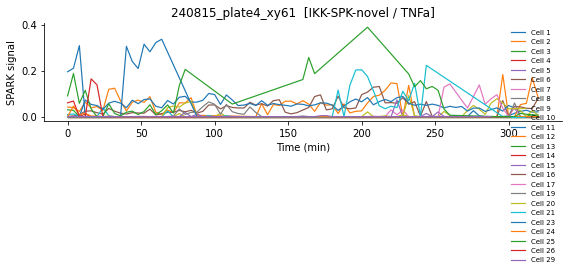

Saving run: 240815_plate4_xy61
  spark_df: 1672 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [01:12<00:00,  1.12it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (402.8 MB)
  done: 240815_plate4_xy61

Processing: 240815_plate4_xy62  [IKK-SPK-novel / TNFa]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=104  max=7916  mean=254.5


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [03:07<00:00,  2.31s/it]


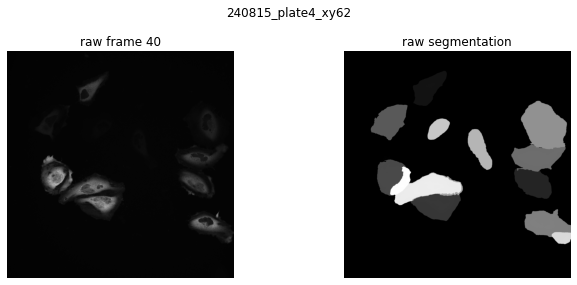

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [01:24<00:00,  1.05s/it]


  cell 1: interpolating frames 74–74
  cell 1: interpolating frames 78–78
  cell 2: interpolating frames 46–46
  cell 2: interpolating frames 76–76
  cell 4: interpolating frames 11–12
  cell 5: interpolating frames 32–32
  cell 5: interpolating frames 45–45
  cell 5: gap 69–73 (5 frames) too large, skipping
  cell 5: interpolating frames 76–77
  cell 6: gap 31–36 (6 frames) too large, skipping
  cell 7: interpolating frames 2–3
  cell 11: gap 1–10 (10 frames) too large, skipping
  cell 11: gap 13–77 (65 frames) too large, skipping
  cell 12: gap 1–16 (16 frames) too large, skipping
tracked_masks: (81, 1608, 1608)  cells=[ 1  2  3  4  5  6  7  8  9 10 11 12 14]


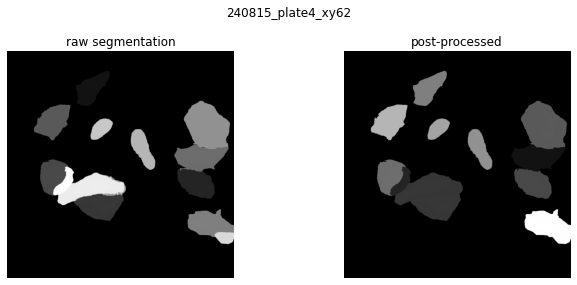

Quantifying 20240815_cy_plate4xy62.tif: 100%|██████████████████████| 81/81 [01:07<00:00,  1.20it/s]


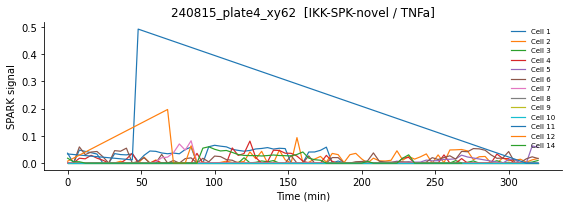

Saving run: 240815_plate4_xy62
  spark_df: 877 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [00:42<00:00,  1.88it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (406.8 MB)
  done: 240815_plate4_xy62

Processing: 240815_plate4_xy63  [IKK-SPK-novel / TNFa]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=102  max=5239  mean=195.5


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [02:47<00:00,  2.07s/it]


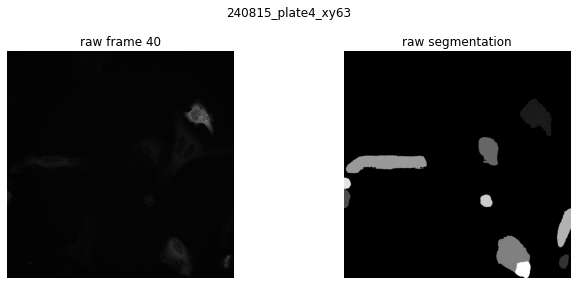

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [00:44<00:00,  1.82it/s]


  cell 1: interpolating frames 61–61
  cell 5: interpolating frames 3–5
  cell 5: interpolating frames 7–7
  cell 5: interpolating frames 11–12
  cell 5: interpolating frames 15–16
  cell 5: interpolating frames 19–19
  cell 5: gap 21–32 (12 frames) too large, skipping
  cell 5: interpolating frames 34–34
  cell 5: interpolating frames 38–38
  cell 5: interpolating frames 40–41
  cell 5: gap 47–52 (6 frames) too large, skipping
  cell 5: interpolating frames 54–54
  cell 5: interpolating frames 61–61
  cell 6: interpolating frames 4–4
  cell 8: interpolating frames 3–4
  cell 8: interpolating frames 11–11
  cell 8: interpolating frames 60–60
tracked_masks: (81, 1608, 1608)  cells=[1 2 3 4 5 6 7 8]


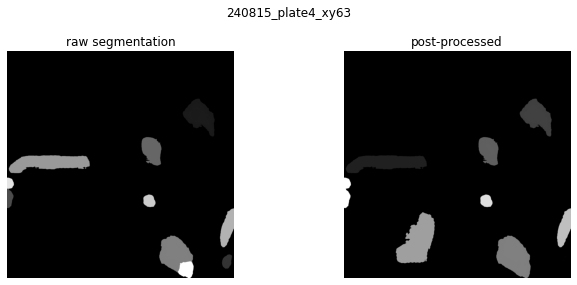

Quantifying 20240815_cy_plate4xy63.tif: 100%|██████████████████████| 81/81 [00:50<00:00,  1.59it/s]


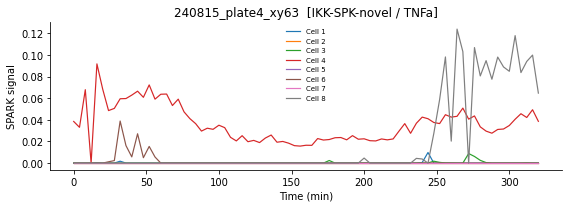

Saving run: 240815_plate4_xy63
  spark_df: 630 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [00:35<00:00,  2.31it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (409.0 MB)
  done: 240815_plate4_xy63

Processing: 240815_plate4_xy64  [IKK-SPK-novel / TNFa]

Selected: grayscale_direct  shape=(81, 1608, 1608)  min=103  max=4533  mean=228.5


CellSAM segmentation: 100%|████████████████████████████████████████| 81/81 [05:14<00:00,  3.89s/it]


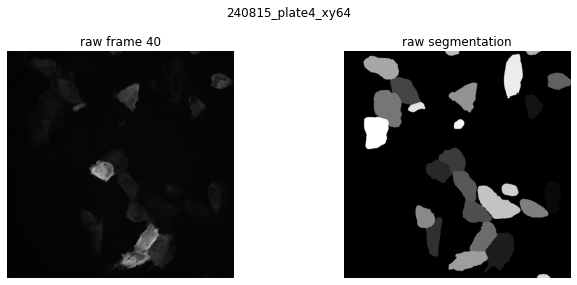

Post-processing masks: 100%|███████████████████████████████████████| 81/81 [04:47<00:00,  3.54s/it]


  cell 5: interpolating frames 62–62
  cell 7: interpolating frames 62–62
  cell 10: interpolating frames 77–77
  cell 12: interpolating frames 15–17
  cell 13: gap 2–45 (44 frames) too large, skipping
  cell 13: interpolating frames 73–73
  cell 13: interpolating frames 76–76
  cell 14: interpolating frames 22–22
  cell 14: gap 38–51 (14 frames) too large, skipping
  cell 14: interpolating frames 62–65
  cell 14: gap 73–77 (5 frames) too large, skipping
  cell 14: interpolating frames 79–79
  cell 15: interpolating frames 19–19
  cell 15: interpolating frames 29–29
  cell 18: interpolating frames 3–3
  cell 18: interpolating frames 6–6
  cell 18: interpolating frames 8–11
  cell 18: interpolating frames 14–16
  cell 18: interpolating frames 19–20
  cell 18: gap 22–54 (33 frames) too large, skipping
  cell 22: interpolating frames 2–3
  cell 25: interpolating frames 6–6
  cell 25: interpolating frames 8–10
  cell 25: interpolating frames 13–13
  cell 29: interpolating frames 33–35
  ce

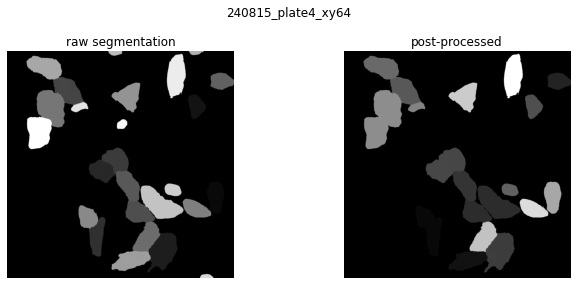

Quantifying 20240815_cy_plate4xy64.tif: 100%|██████████████████████| 81/81 [01:44<00:00,  1.29s/it]


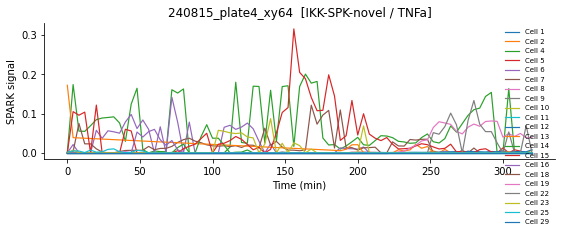

Saving run: 240815_plate4_xy64
  spark_df: 1580 rows × 14 cols
  tracked_masks: (81, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 81/81 [01:08<00:00,  1.18it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (413.9 MB)
  done: 240815_plate4_xy64

Processing: 240822_plate2_xy36  [IKK-SPK-novel / blank]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=97  max=1806  mean=184.0


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [01:49<00:00,  1.80s/it]


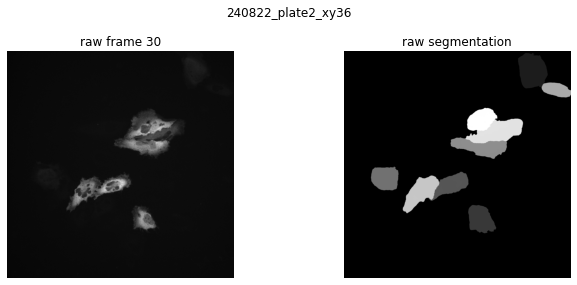

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:23<00:00,  2.61it/s]


  cell 1: interpolating frames 39–40
  cell 1: interpolating frames 43–43
  cell 1: interpolating frames 45–45
  cell 2: interpolating frames 40–40
  cell 4: interpolating frames 15–15
  cell 4: interpolating frames 36–36
  cell 4: interpolating frames 38–38
  cell 4: interpolating frames 52–52
  cell 6: interpolating frames 1–3
  cell 6: interpolating frames 9–9
  cell 6: interpolating frames 25–26
  cell 6: interpolating frames 28–29
  cell 6: interpolating frames 32–32
  cell 6: interpolating frames 43–44
  cell 6: interpolating frames 46–46
  cell 6: interpolating frames 49–50
  cell 7: interpolating frames 4–4
  cell 7: interpolating frames 25–26
  cell 7: interpolating frames 29–29
  cell 7: gap 36–46 (11 frames) too large, skipping
  cell 7: gap 49–53 (5 frames) too large, skipping
  cell 7: interpolating frames 55–55
tracked_masks: (61, 1608, 1608)  cells=[1 2 3 4 5 6 7]


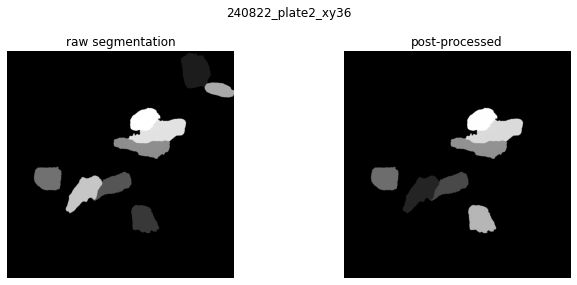

Quantifying 20240822_cy_plate2c1xy36.tif: 100%|████████████████████| 61/61 [00:33<00:00,  1.82it/s]


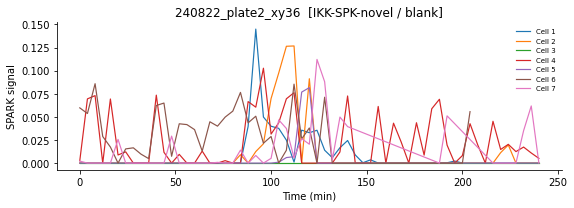

Saving run: 240822_plate2_xy36
  spark_df: 402 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:22<00:00,  2.66it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (415.6 MB)
  done: 240822_plate2_xy36

Processing: 240822_plate2_xy37  [IKK-SPK-novel / blank]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=99  max=2371  mean=167.6


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [01:28<00:00,  1.45s/it]


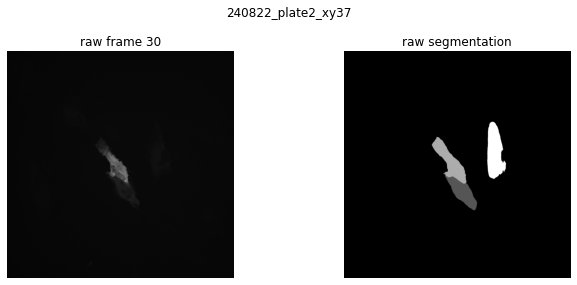

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:09<00:00,  6.47it/s]


  cell 2: interpolating frames 5–6
  cell 3: interpolating frames 10–10
  cell 3: interpolating frames 21–21
tracked_masks: (61, 1608, 1608)  cells=[1 2 3]


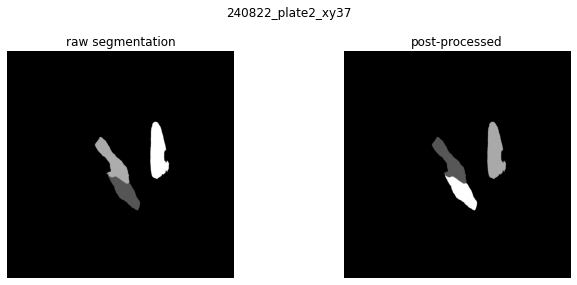

Quantifying 20240822_cy_plate2c1xy37.tif: 100%|████████████████████| 61/61 [00:17<00:00,  3.47it/s]


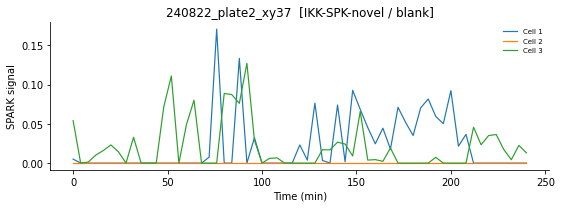

Saving run: 240822_plate2_xy37
  spark_df: 183 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:14<00:00,  4.35it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (416.7 MB)
  done: 240822_plate2_xy37

Processing: 240822_plate2_xy38  [IKK-SPK-novel / GSK-8612]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=97  max=636  mean=152.6


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [01:31<00:00,  1.50s/it]


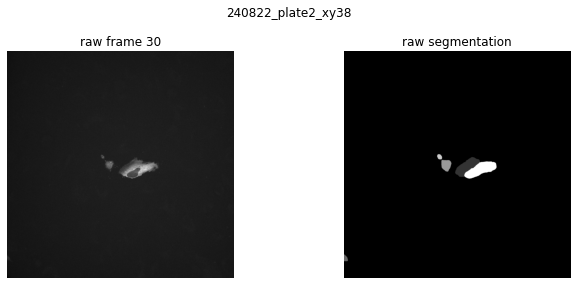

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:10<00:00,  5.71it/s]


  cell 2: interpolating frames 34–34
  cell 2: interpolating frames 41–42
  cell 2: interpolating frames 51–51
  cell 4: interpolating frames 5–6
tracked_masks: (61, 1608, 1608)  cells=[2 4]


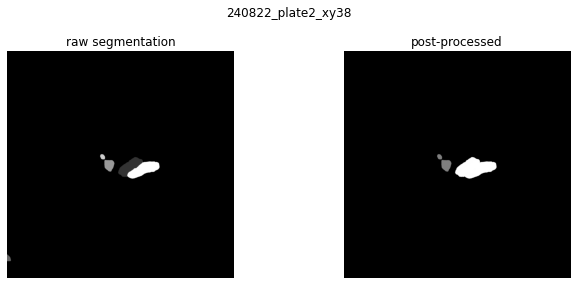

Quantifying 20240822_cy_plate2c1xy38.tif: 100%|████████████████████| 61/61 [00:14<00:00,  4.34it/s]


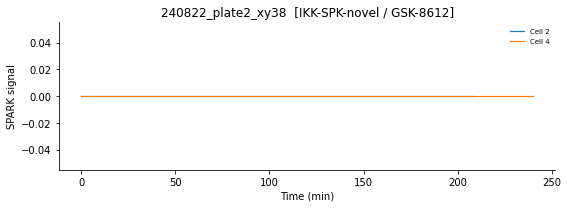

Saving run: 240822_plate2_xy38
  spark_df: 114 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:11<00:00,  5.15it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (417.2 MB)
  done: 240822_plate2_xy38

Processing: 240822_plate2_xy39  [IKK-SPK-novel / GSK-8612]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=94  max=1197  mean=154.8


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [01:28<00:00,  1.44s/it]


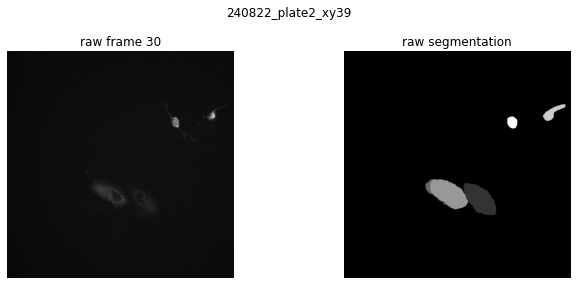

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:10<00:00,  5.67it/s]


  cell 2: interpolating frames 52–52
  cell 2: interpolating frames 57–57
  cell 3: interpolating frames 13–13
  cell 3: interpolating frames 36–36
  cell 4: interpolating frames 26–26
  cell 4: gap 28–32 (5 frames) too large, skipping
  cell 4: interpolating frames 34–37
  cell 4: interpolating frames 54–54
tracked_masks: (61, 1608, 1608)  cells=[1 2 3 4]


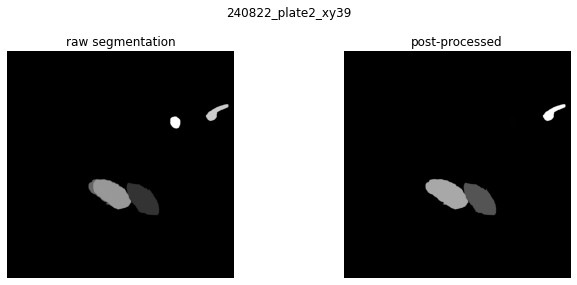

Quantifying 20240822_cy_plate2c1xy39.tif: 100%|████████████████████| 61/61 [00:22<00:00,  2.76it/s]


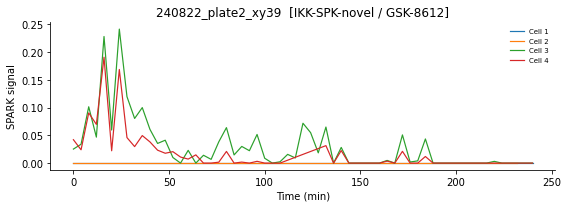

Saving run: 240822_plate2_xy39
  spark_df: 237 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:16<00:00,  3.70it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (418.1 MB)
  done: 240822_plate2_xy39

Processing: 240822_plate2_xy41  [IKK-SPK-novel / BMS-345541]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=98  max=1402  mean=157.2


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [01:14<00:00,  1.21s/it]


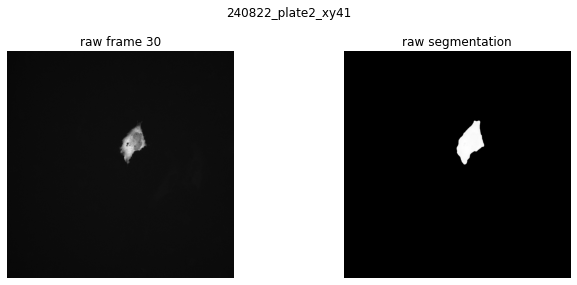

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:05<00:00, 10.28it/s]


tracked_masks: (61, 1608, 1608)  cells=[1]


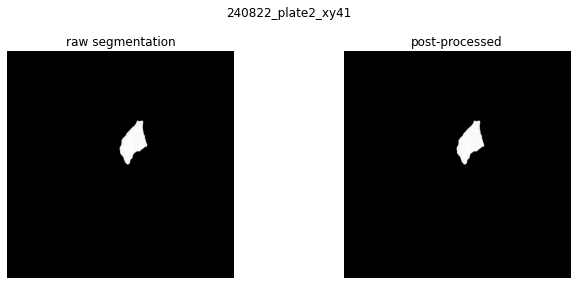

Quantifying 20240822_cy_plate2c1xy41.tif: 100%|████████████████████| 61/61 [00:11<00:00,  5.43it/s]


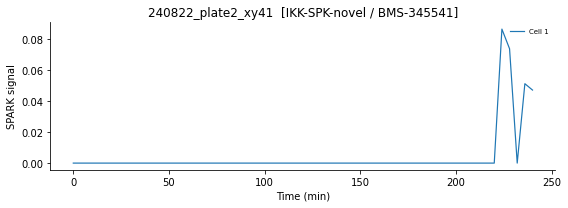

Saving run: 240822_plate2_xy41
  spark_df: 61 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:09<00:00,  6.40it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (418.8 MB)
  done: 240822_plate2_xy41

Processing: 240822_plate2_xy44  [IKK-SPK-novel / TNFa]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=98  max=4035  mean=155.3


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [01:35<00:00,  1.56s/it]


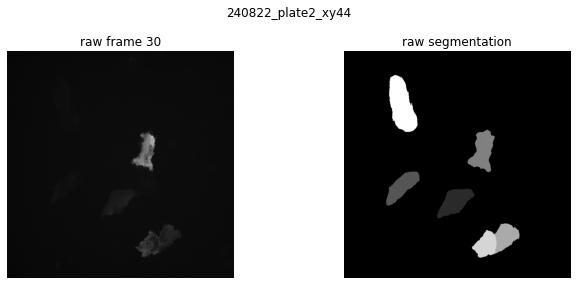

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:17<00:00,  3.53it/s]


  cell 2: interpolating frames 1–1
  cell 3: interpolating frames 1–3
  cell 3: interpolating frames 7–7
tracked_masks: (61, 1608, 1608)  cells=[1 2 3]


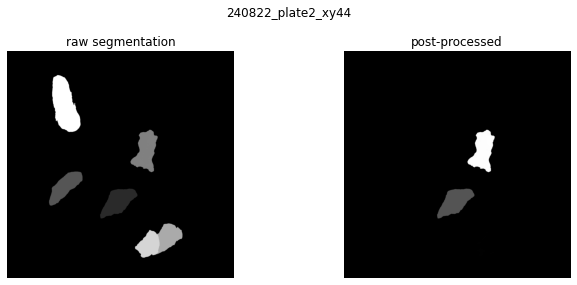

Quantifying 20240822_cy_plate2c1xy44.tif: 100%|████████████████████| 61/61 [00:15<00:00,  3.87it/s]


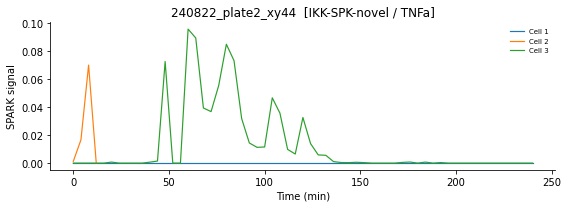

Saving run: 240822_plate2_xy44
  spark_df: 126 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:12<00:00,  4.91it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (419.6 MB)
  done: 240822_plate2_xy44

Processing: 240822_plate2_xy45  [IKK-SPK-novel / TNFa]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=95  max=1590  mean=153.9


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [01:27<00:00,  1.44s/it]


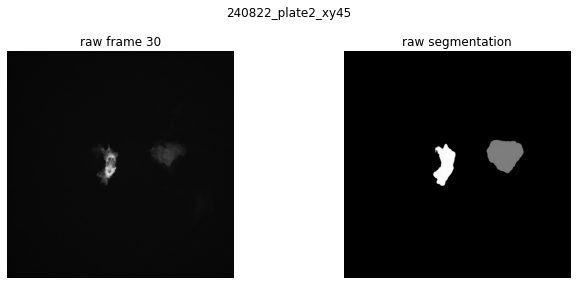

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:11<00:00,  5.12it/s]


  cell 2: gap 12–18 (7 frames) too large, skipping
  cell 3: gap 27–33 (7 frames) too large, skipping
  cell 3: interpolating frames 52–52
tracked_masks: (61, 1608, 1608)  cells=[1 2 3 4]


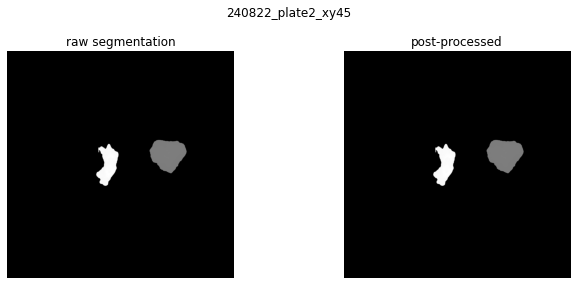

Quantifying 20240822_cy_plate2c1xy45.tif: 100%|████████████████████| 61/61 [00:19<00:00,  3.15it/s]


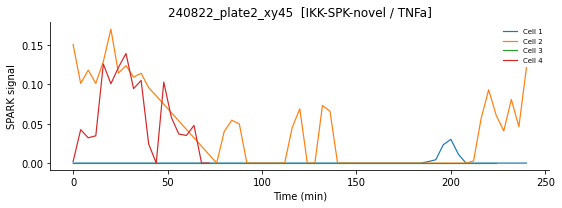

Saving run: 240822_plate2_xy45
  spark_df: 184 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:14<00:00,  4.07it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (420.5 MB)
  done: 240822_plate2_xy45

Processing: 240822_plate2_xy46  [IKK-SPK-novel / TNFa]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=94  max=1229  mean=157.0


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [02:11<00:00,  2.15s/it]


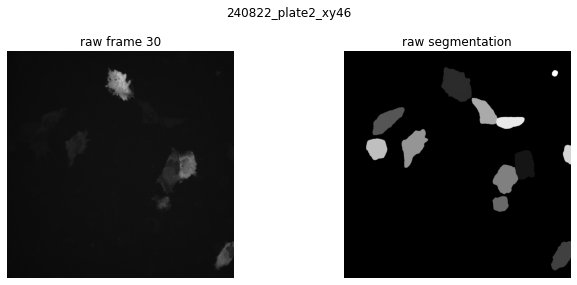

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:38<00:00,  1.58it/s]


  cell 5: interpolating frames 35–35
  cell 5: interpolating frames 43–43
  cell 7: interpolating frames 11–14
tracked_masks: (61, 1608, 1608)  cells=[1 2 3 4 5 6 7]


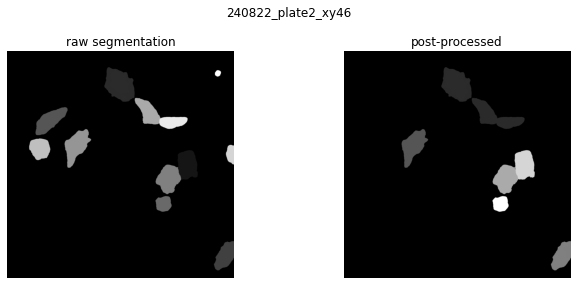

Quantifying 20240822_cy_plate2c1xy46.tif: 100%|████████████████████| 61/61 [00:30<00:00,  2.00it/s]


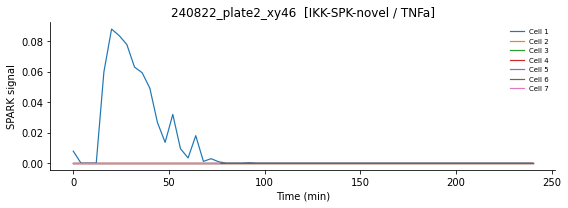

Saving run: 240822_plate2_xy46
  spark_df: 386 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:22<00:00,  2.74it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (421.5 MB)
  done: 240822_plate2_xy46

Processing: 240822_plate2_xy47  [IKK-SPK-novel / TNFa]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=90  max=3901  mean=153.0


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [01:33<00:00,  1.53s/it]


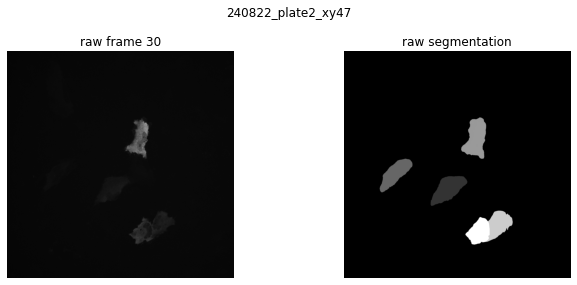

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:11<00:00,  5.14it/s]


  cell 2: interpolating frames 4–4
  cell 3: interpolating frames 2–4
tracked_masks: (61, 1608, 1608)  cells=[1 2 3 4]


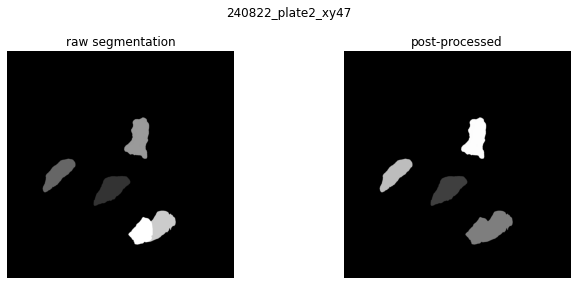

Quantifying 20240822_cy_plate2c1xy47.tif: 100%|████████████████████| 61/61 [00:22<00:00,  2.70it/s]


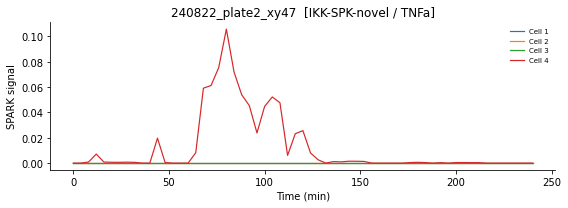

Saving run: 240822_plate2_xy47
  spark_df: 244 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:17<00:00,  3.55it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (422.5 MB)
  done: 240822_plate2_xy47

Processing: 240822_plate2_xy48  [IKK-SPK-novel / polyIC]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=97  max=3420  mean=159.1


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [01:38<00:00,  1.61s/it]


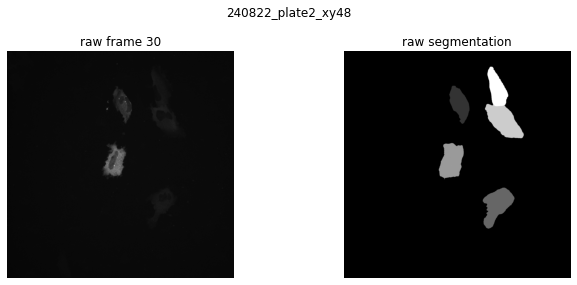

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:12<00:00,  4.73it/s]


  cell 4: gap 53–57 (5 frames) too large, skipping
tracked_masks: (61, 1608, 1608)  cells=[1 2 3 4]


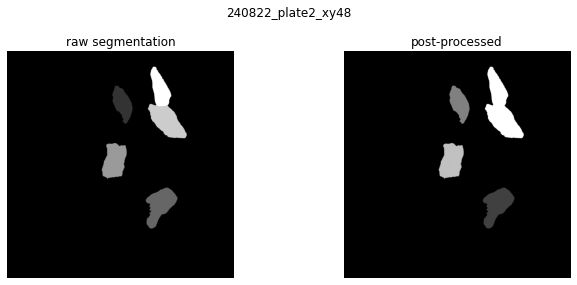

Quantifying 20240822_cy_plate2c1xy48.tif: 100%|████████████████████| 61/61 [00:22<00:00,  2.73it/s]


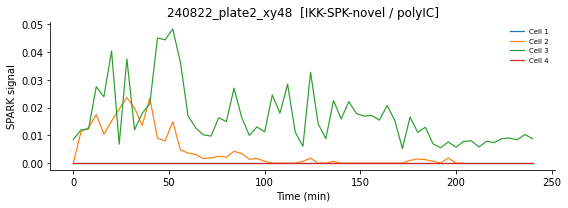

Saving run: 240822_plate2_xy48
  spark_df: 230 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:16<00:00,  3.76it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (423.6 MB)
  done: 240822_plate2_xy48

Processing: 240822_plate2_xy49  [IKK-SPK-novel / polyIC]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=95  max=2696  mean=169.4


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [01:51<00:00,  1.84s/it]


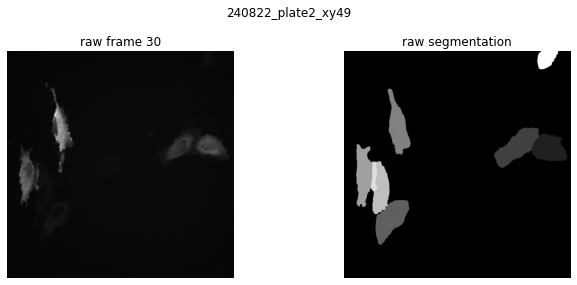

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:28<00:00,  2.11it/s]


  cell 3: gap 10–38 (29 frames) too large, skipping
  cell 3: gap 41–49 (9 frames) too large, skipping
  cell 3: interpolating frames 51–51
  cell 4: interpolating frames 41–43
  cell 4: interpolating frames 51–53
  cell 4: interpolating frames 55–55
  cell 5: interpolating frames 47–47
  cell 7: interpolating frames 22–22
  cell 7: interpolating frames 24–25
  cell 7: interpolating frames 28–29
  cell 7: interpolating frames 34–34
tracked_masks: (61, 1608, 1608)  cells=[1 2 3 4 5 6 7 8 9]


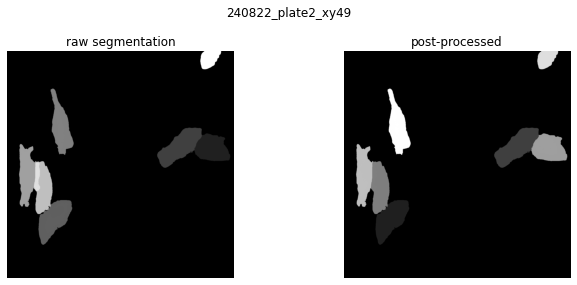

Quantifying 20240822_cy_plate2c1xy49.tif: 100%|████████████████████| 61/61 [00:35<00:00,  1.70it/s]


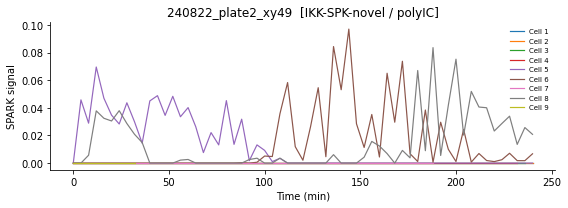

Saving run: 240822_plate2_xy49
  spark_df: 443 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:24<00:00,  2.49it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (425.1 MB)
  done: 240822_plate2_xy49

Processing: 240822_plate2_xy50  [IKK-SPK-novel / polyIC]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=97  max=2902  mean=165.4


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [02:05<00:00,  2.06s/it]


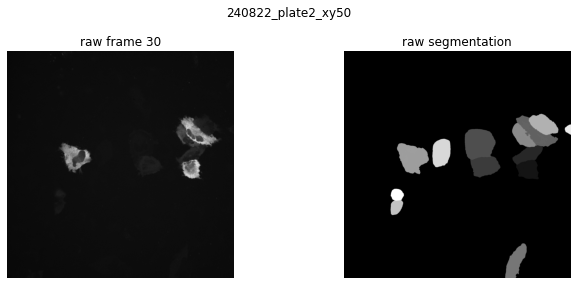

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:32<00:00,  1.90it/s]


  cell 2: gap 24–36 (13 frames) too large, skipping
  cell 4: interpolating frames 27–27
  cell 4: interpolating frames 46–46
  cell 5: gap 38–47 (10 frames) too large, skipping
  cell 6: interpolating frames 2–2
  cell 6: interpolating frames 13–13
  cell 6: interpolating frames 15–15
  cell 6: interpolating frames 36–36
  cell 6: interpolating frames 38–38
  cell 6: interpolating frames 45–46
  cell 7: interpolating frames 1–1
  cell 7: interpolating frames 21–22
tracked_masks: (61, 1608, 1608)  cells=[1 2 3 4 5 6 7]


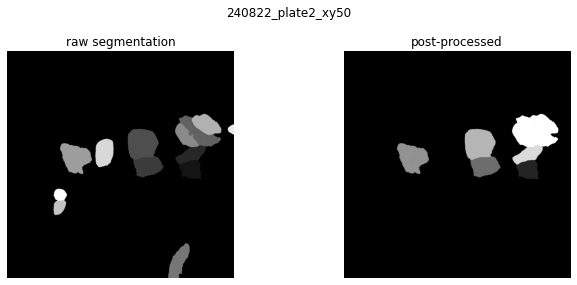

Quantifying 20240822_cy_plate2c1xy50.tif: 100%|████████████████████| 61/61 [00:29<00:00,  2.08it/s]


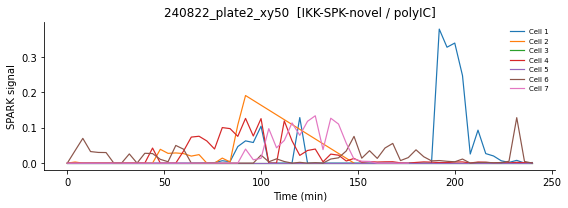

Saving run: 240822_plate2_xy50
  spark_df: 365 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:20<00:00,  2.94it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (426.6 MB)
  done: 240822_plate2_xy50

Processing: 240822_plate2_xy51  [IKK-SPK-novel / polyIC]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=92  max=954  mean=154.5


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [01:45<00:00,  1.74s/it]


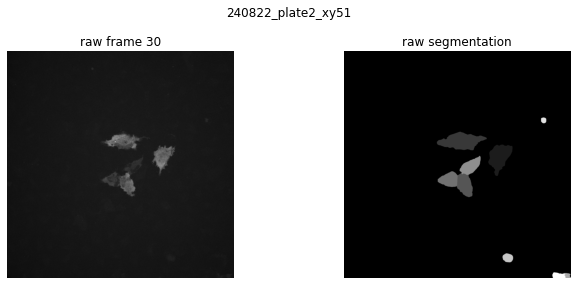

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:16<00:00,  3.77it/s]


  cell 3: interpolating frames 51–51
tracked_masks: (61, 1608, 1608)  cells=[1 2 3 4 7]


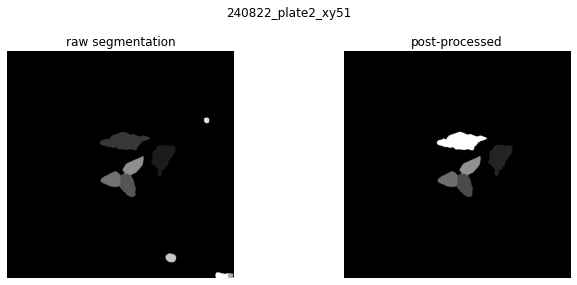

Quantifying 20240822_cy_plate2c1xy51.tif: 100%|████████████████████| 61/61 [00:25<00:00,  2.44it/s]


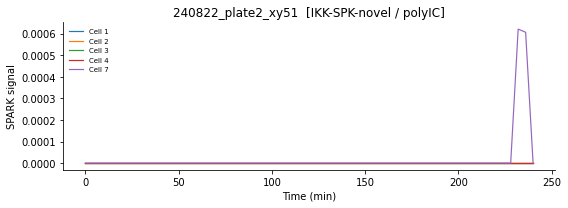

Saving run: 240822_plate2_xy51
  spark_df: 305 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:18<00:00,  3.25it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (427.3 MB)
  done: 240822_plate2_xy51

Processing: 240822_plate2_xy52  [IKK-SPK-novel / polyIC]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=95  max=2743  mean=166.5


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [01:51<00:00,  1.83s/it]


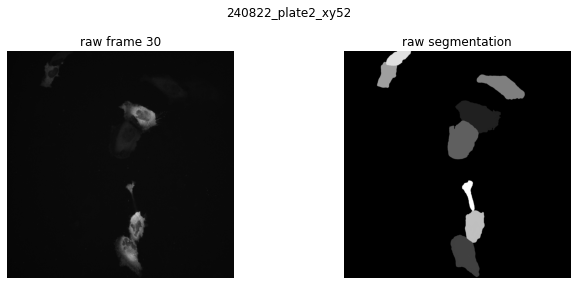

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:19<00:00,  3.12it/s]


  cell 4: interpolating frames 46–46
  cell 7: interpolating frames 33–36
  cell 7: gap 45–52 (8 frames) too large, skipping
  cell 7: interpolating frames 56–56
tracked_masks: (61, 1608, 1608)  cells=[1 2 3 4 5 6 7]


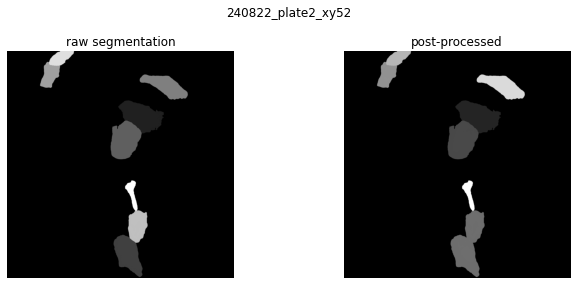

Quantifying 20240822_cy_plate2c1xy52.tif: 100%|████████████████████| 61/61 [00:34<00:00,  1.78it/s]


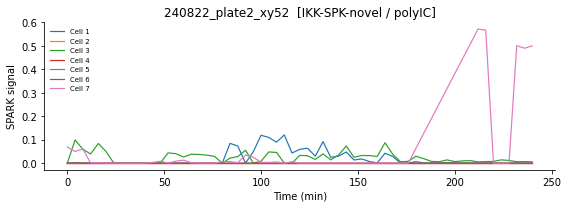

Saving run: 240822_plate2_xy52
  spark_df: 419 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:23<00:00,  2.65it/s]


Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (428.8 MB)
  done: 240822_plate2_xy52

All IKK-SPK-novel runs reprocessed.


In [14]:
# ── improved SPARK quantification for dim IKK-SPK-novel reporter ──────────────
from skimage import measure
from skimage.morphology import remove_small_objects
from scipy.ndimage import label as scipy_label
import tifffile
import numpy as np
import pandas as pd
from tqdm import tqdm

PUNCTA_CELL_PERCENTILE = 99
PUNCTA_LOW_FLOOR       = 800
MIN_PUNCTA_SIZE        = 5
MAX_PUNCTA_SIZE        = 1500
MIN_PUNCTA_MEAN_INT    = 750
SEED_THRESH_CAP        = 1200


def quantify_spark_dim(path, tracked_masks, minutes_per_frame, frame_offset_min):
    """
    Two-threshold SPARK quantification for dim reporters (v2).
    - Seeds at per-cell p99, capped at SEED_THRESH_CAP to avoid hotspot inflation
    - Expands each seed to connected pixels >= PUNCTA_LOW_FLOOR (labeled once)
    - Filters expanded objects by size and mean intensity
    """
    n_frames = tracked_masks.shape[0]
    records  = []

    for t in tqdm(range(n_frames), desc=f'Quantifying {os.path.basename(path)}'):
        frame_img   = tifffile.imread(path, key=t).astype(np.float32)
        label_frame = tracked_masks[t]
        cell_ids    = np.unique(label_frame)
        cell_ids    = cell_ids[cell_ids != 0]

        for cid in cell_ids:
            cell_mask  = (label_frame == cid)
            cell_px    = frame_img[cell_mask]
            cell_total = float(cell_px.sum())
            cell_area  = int(cell_mask.sum())

            cell_thresh = min(np.percentile(cell_px, PUNCTA_CELL_PERCENTILE),
                              SEED_THRESH_CAP)
            seed_mask   = (frame_img >= cell_thresh) & cell_mask
            seed_mask   = remove_small_objects(seed_mask, min_size=MIN_PUNCTA_SIZE)

            if not seed_mask.any():
                records.append({
                    'frame': t, 'time_min': frame_offset_min + t * minutes_per_frame,
                    'cell_id': int(cid), 'cell_area_px': cell_area,
                    'cell_total_int': cell_total, 'cell_thresh': float(cell_thresh),
                    'puncta_count': 0, 'puncta_area_px': 0,
                    'puncta_total_int': 0.0, 'spark_signal': 0.0,
                })
                continue

            low_mask           = (frame_img >= PUNCTA_LOW_FLOOR) & cell_mask
            low_labeled, _     = scipy_label(low_mask)
            seed_labels        = measure.label(seed_mask)
            claimed            = np.zeros_like(low_mask, dtype=bool)

            for seed_lbl in range(1, seed_labels.max() + 1):
                touching = np.unique(low_labeled[seed_labels == seed_lbl])
                touching = touching[touching != 0]
                for lbl in touching:
                    claimed |= (low_labeled == lbl)
            claimed &= cell_mask

            exp_labeled = measure.label(claimed)
            final_mask  = np.zeros_like(claimed, dtype=bool)
            for r in measure.regionprops(exp_labeled, intensity_image=frame_img):
                if (MIN_PUNCTA_SIZE <= r.area <= MAX_PUNCTA_SIZE and
                        r.mean_intensity >= MIN_PUNCTA_MEAN_INT):
                    final_mask[exp_labeled == r.label] = True

            final_labeled    = measure.label(final_mask)
            puncta_total     = float(frame_img[final_mask].sum())
            puncta_count     = int(final_labeled.max())
            puncta_area      = int(final_mask.sum())
            spark_signal     = puncta_total / cell_total if cell_total > 0 else np.nan

            records.append({
                'frame': t, 'time_min': frame_offset_min + t * minutes_per_frame,
                'cell_id': int(cid), 'cell_area_px': cell_area,
                'cell_total_int': cell_total, 'cell_thresh': float(cell_thresh),
                'puncta_count': puncta_count, 'puncta_area_px': puncta_area,
                'puncta_total_int': puncta_total, 'spark_signal': spark_signal,
            })

    return pd.DataFrame(records)

def already_processed(h5_path, key):
    if not os.path.exists(h5_path):
        return False
    with h5py.File(h5_path, 'r') as hf:
        return key in hf


for exp in EXPERIMENTS:
    path    = exp['path']
    run_key = exp['run_key']
    sep     = '=' * 60

    if already_processed(OUTPUT_H5, run_key):
        print(f'Skipping {run_key} (already in HDF5)')
        continue

    print(f'\n{sep}')
    print(f'Processing: {run_key}  [{exp["reporter"]} / {exp["condition"]}]')
    print(sep)

    # 1. load
    arr, meta = load_tiff_as_grayscale(path, channel=exp.get('channel'))
    read_frame_fn = make_read_frame(path, meta)

    # 2. segmentation (same as original pipeline)
    masks_raw = run_cellsam_segmentation(model, arr, clip_max=SEG_PARAMS['clip_max'])

    t_qc = arr.shape[0] // 2
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(arr[t_qc], cmap='gray'); axes[0].set_title(f'raw frame {t_qc}')
    axes[1].imshow(masks_raw[t_qc] * 2000 + arr[t_qc] * 0.1, cmap='gray')
    axes[1].set_title('raw segmentation')
    for ax in axes: ax.axis('off')
    plt.suptitle(run_key); plt.tight_layout(); plt.show()

    # 3. post-processing
    masks_clean, origin_frame = postprocess_masks(
        masks_raw,
        min_cell_size_px = SEG_PARAMS['min_cell_size_px'],
        iou_thresh       = SEG_PARAMS['iou_thresh'],
        ioq_thresh       = SEG_PARAMS['ioq_thresh'],
        dilation_px      = SEG_PARAMS['dilation_px'],
    )
    expected_ids = list(np.unique(origin_frame)[1:])
    masks_clean  = interpolate_missing_masks(
        masks_clean, expected_ids, max_gap=SEG_PARAMS['max_interp_gap'])
    tracked_masks = np.array(masks_clean)
    print(f'tracked_masks: {tracked_masks.shape}  cells={np.unique(tracked_masks)[1:]}')

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(masks_raw[t_qc] * 2000 + arr[t_qc] * 0.1, cmap='gray')
    axes[0].set_title('raw segmentation')
    axes[1].imshow(tracked_masks[t_qc] * 2000 + arr[t_qc] * 0.1, cmap='gray')
    axes[1].set_title('post-processed')
    for ax in axes: ax.axis('off')
    plt.suptitle(run_key); plt.tight_layout(); plt.show()

    # 4. SPARK quantification — improved two-threshold method
    df_spark = quantify_spark_dim(
        path, tracked_masks,
        minutes_per_frame = exp['minutes_per_frame'],
        frame_offset_min  = exp['frame_offset_min'],
    )

    # 5. normalisation
    df_spark = normalise_spark(
        df_spark,
        norm_frame    = exp.get('norm_frame'),
        ctrl_cell_ids = exp.get('ctrl_cell_ids'),
    )
    df_spark['reporter']  = exp['reporter']
    df_spark['condition'] = exp['condition']

    # quick trace preview
    fig, ax = plt.subplots(figsize=(8, 3))
    for cid, grp in df_spark.groupby('cell_id'):
        ax.plot(grp['time_min'], grp['spark_norm_ctrl'], lw=1.2, label=f'Cell {cid}')
    ax.set_xlabel('Time (min)'); ax.set_ylabel('SPARK signal')
    ax.legend(fontsize=7, frameon=False)
    ax.spines[['top','right']].set_visible(False)
    ax.set_title(f'{run_key}  [{exp["reporter"]} / {exp["condition"]}]')
    plt.tight_layout(); plt.show()

    # 6. save
    full_params = {
        'puncta_cell_percentile': PUNCTA_CELL_PERCENTILE,
        'puncta_low_floor':       PUNCTA_LOW_FLOOR,
        'min_puncta_size':        MIN_PUNCTA_SIZE,
        'max_puncta_size':        MAX_PUNCTA_SIZE,
        'min_puncta_mean_int':    MIN_PUNCTA_MEAN_INT,
        'minutes_per_frame':      exp['minutes_per_frame'],
        'frame_offset_min':       exp['frame_offset_min'],
        'norm_frame':             str(exp.get('norm_frame')),
        'ctrl_cell_ids':          str(exp.get('ctrl_cell_ids')),
        'reporter':               exp['reporter'],
        'condition':              exp['condition'],
    }
    save_to_hdf5(OUTPUT_H5, run_key, path, df_spark,
                 tracked_masks, read_frame_fn, full_params)
    print(f'  done: {run_key}')

print('\nAll IKK-SPK-novel runs reprocessed.')
